# Wind Power Forecasting — Pure LSTM Hyperparameter Experiments

**Goal:** Forecast `Wind_MW` using a **6-hour lookback window**.
**Train:** 2023 + 2024 &nbsp;|&nbsp; **Test:** 2025

## What varies across experiments
Only a **single standard LSTM → Linear** architecture is used (pure LSTM, no attention / CNN / hybrid blocks).
The experiments sweep over two axes, capped as requested:


Nine configurations are trained and compared on MAE, RMSE, R², and MAPE.

## Feature Set (12 features)
| Group | Features |
|-------|----------|
| Autoregressive | `Wind_MW` |
| Weather | `WS10M` (corr 0.57 — dominant driver), `T2M`, `RH2M`, `CLOUD_AMT` |
| Cyclic time | `Hour_sin/cos`, `DayOfYear_sin/cos`, `Month_sin/cos`, `DayOfWeek_sin/cos` |


> Unlike the solar dataset, there is no irradiance data here — wind speed (`WS10M`) plays the
> role that irradiance played for solar, as the single strongest physical driver of generation.


## Step 1 — Imports & Configuration

In [1]:
# ============================================================
# STEP 1 — IMPORTS & CONFIGURATION
# ============================================================

import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
import joblib

# ── Reproducibility ──
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# ── Fixed hyperparameters ──
WIND_LOOKBACK  = 6        # 6-hour lookback window
BATCH_SIZE     = 64
EPOCHS         = 30
PATIENCE       = 10       # early-stopping patience
LR             = 1e-3
DATA_PATH      = 'Wind_Forecasting.csv'
OUTPUT_DIR     = 'wind_results'
os.makedirs(OUTPUT_DIR, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {device}')
if torch.cuda.is_available():
    print(f'GPU    : {torch.cuda.get_device_name(0)}')


Device : cpu


## Step 2 — Load Data & Engineer Cyclic Features

In [2]:
# ============================================================
# STEP 2 — LOAD DATA
# ============================================================

wind_df = pd.read_csv(DATA_PATH)
wind_df['Datetime_UTC'] = pd.to_datetime(
    wind_df['Datetime_UTC'], utc=True
)
wind_df = wind_df.sort_values('Datetime_UTC').reset_index(drop=True)

print(f'Rows  : {len(wind_df)}')
print(f'Start : {wind_df["Datetime_UTC"].min()}')
print(f'End   : {wind_df["Datetime_UTC"].max()}')
wind_df.head(3)


Rows  : 26297
Start : 2023-01-01 07:00:00+00:00
End   : 2025-12-31 23:00:00+00:00


,Datetime_UTC,Wind_MW,T2M,RH2M,WS10M,CLOUD_AMT,Hour,DayOfWeek,DayOfYear,Month
0,2023-01-01 07:00:00+00:00,21753.284477,11.32,69.29,5.05,2.37,7,6,1,1
1,2023-01-01 08:00:00+00:00,21570.395694,10.36,75.44,4.62,10.12,8,6,1,1
2,2023-01-01 09:00:00+00:00,21036.504013,9.76,79.94,4.48,17.85,9,6,1,1


In [3]:
# ============================================================
# STEP 2.1 — CYCLIC FEATURE ENGINEERING
# ============================================================
# sin/cos encoding keeps the circular nature of time:
# hour 23 and hour 0 are adjacent, not distant.

wind_df['Hour_sin']      = np.sin(2 * np.pi * wind_df['Hour']      / 24)
wind_df['Hour_cos']      = np.cos(2 * np.pi * wind_df['Hour']      / 24)
wind_df['DayOfYear_sin'] = np.sin(2 * np.pi * wind_df['DayOfYear'] / 365.25)
wind_df['DayOfYear_cos'] = np.cos(2 * np.pi * wind_df['DayOfYear'] / 365.25)
wind_df['Month_sin']     = np.sin(2 * np.pi * wind_df['Month']     / 12)
wind_df['Month_cos']     = np.cos(2 * np.pi * wind_df['Month']     / 12)
wind_df['DayOfWeek_sin'] = np.sin(2 * np.pi * wind_df['DayOfWeek'] / 7)
wind_df['DayOfWeek_cos'] = np.cos(2 * np.pi * wind_df['DayOfWeek'] / 7)

print('Cyclic features added.')


Cyclic features added.


In [4]:
# ============================================================
# STEP 2.2 — FEATURE SET & TARGET
# ============================================================

WIND_FEATURES = [
    # Autoregressive
    'Wind_MW',

    # Weather
    'WS10M',                # wind speed at 10m   (corr = 0.57, dominant driver)
    'T2M',                  # temperature
    'RH2M',                 # humidity
    'CLOUD_AMT',            # cloud cover

    # Cyclic time
    'Hour_sin',
    'Hour_cos',
    'DayOfYear_sin',
    'DayOfYear_cos',
    'Month_sin',
    'Month_cos',
    'DayOfWeek_sin',
    'DayOfWeek_cos',
]
WIND_TARGET = 'Wind_MW'

print(f'Total features : {len(WIND_FEATURES)}')
print(f'Target         : {WIND_TARGET}')
for i, f in enumerate(WIND_FEATURES, 1):
    print(f'  {i:02d}. {f}')


Total features : 13
Target         : Wind_MW
  01. Wind_MW
  02. WS10M
  03. T2M
  04. RH2M
  05. CLOUD_AMT
  06. Hour_sin
  07. Hour_cos
  08. DayOfYear_sin
  09. DayOfYear_cos
  10. Month_sin
  11. Month_cos
  12. DayOfWeek_sin
  13. DayOfWeek_cos


## Step 3 — Train / Test Split

In [5]:
# ============================================================
# STEP 3 — TRAIN / TEST SPLIT
# Train: 2023 + 2024  |  Test: 2025
# ============================================================

wind_train = wind_df[wind_df['Datetime_UTC'].dt.year < 2025].copy()
wind_test  = wind_df[wind_df['Datetime_UTC'].dt.year == 2025].copy()

print('TRAIN')
print(f'  Start : {wind_train["Datetime_UTC"].min()}')
print(f'  End   : {wind_train["Datetime_UTC"].max()}')
print(f'  Rows  : {len(wind_train)}')

print('\nTEST')
print(f'  Start : {wind_test["Datetime_UTC"].min()}')
print(f'  End   : {wind_test["Datetime_UTC"].max()}')
print(f'  Rows  : {len(wind_test)}')

overlap = set(wind_train['Datetime_UTC']).intersection(
    set(wind_test['Datetime_UTC'])
)
print(f'\nOverlapping timestamps : {len(overlap)}  (expect 0)')


TRAIN
  Start : 2023-01-01 07:00:00+00:00
  End   : 2024-12-31 23:00:00+00:00
  Rows  : 17537

TEST
  Start : 2025-01-01 00:00:00+00:00
  End   : 2025-12-31 23:00:00+00:00
  Rows  : 8760

Overlapping timestamps : 0  (expect 0)


## Step 4 — Scaling

In [6]:
# ============================================================
# STEP 4 — FEATURE & TARGET SCALING
# Fit ONLY on training data; transform both sets with same scaler.
# ============================================================

X_scaler = StandardScaler()
y_scaler = StandardScaler()

train_X = X_scaler.fit_transform(wind_train[WIND_FEATURES])
test_X  = X_scaler.transform(wind_test[WIND_FEATURES])

train_y = y_scaler.fit_transform(
    wind_train[[WIND_TARGET]]
).flatten()
test_y  = y_scaler.transform(
    wind_test[[WIND_TARGET]]
).flatten()

joblib.dump(X_scaler, os.path.join(OUTPUT_DIR, 'wind_X_scaler.pkl'))
joblib.dump(y_scaler, os.path.join(OUTPUT_DIR, 'wind_y_scaler.pkl'))

print(f'train_X : {train_X.shape}')
print(f'test_X  : {test_X.shape}')
print(f'train_y : {train_y.shape}')
print(f'test_y  : {test_y.shape}')


train_X : (17537, 13)
test_X  : (8760, 13)
train_y : (17537,)
test_y  : (8760,)


## Step 5 — Create LSTM Sequences

In [7]:
# ============================================================
# STEP 5 — CREATE LSTM SEQUENCES
# ============================================================

def create_sequences(X, y, lookback):
    """Sliding-window sequences for training."""
    X_seq, y_seq = [], []
    for i in range(lookback, len(X)):
        X_seq.append(X[i - lookback:i])
        y_seq.append(y[i])
    return (
        np.array(X_seq, dtype=np.float32),
        np.array(y_seq, dtype=np.float32),
    )


def create_test_sequences(train_X, train_y, test_X, test_y, lookback):
    """
    Prepend last `lookback` training rows so the first
    test prediction has full historical context.
    """
    combined_X = np.concatenate([train_X[-lookback:], test_X], axis=0)
    combined_y = np.concatenate([train_y[-lookback:], test_y], axis=0)
    X_seq, y_seq = [], []
    for i in range(lookback, len(combined_X)):
        X_seq.append(combined_X[i - lookback:i])
        y_seq.append(combined_y[i])
    return (
        np.array(X_seq, dtype=np.float32),
        np.array(y_seq, dtype=np.float32),
    )


X_train_seq, y_train_seq = create_sequences(
    train_X, train_y, WIND_LOOKBACK
)
X_test_seq, y_test_seq = create_test_sequences(
    train_X, train_y, test_X, test_y, WIND_LOOKBACK
)

print('Sequence shapes:')
print(f'  X_train : {X_train_seq.shape}   y_train : {y_train_seq.shape}')
print(f'  X_test  : {X_test_seq.shape}    y_test  : {y_test_seq.shape}')


Sequence shapes:
  X_train : (17531, 6, 13)   y_train : (17531,)
  X_test  : (8760, 6, 13)    y_test  : (8760,)


## Step 6 — PyTorch Datasets & DataLoaders

In [8]:
# ============================================================
# STEP 6 — DATASETS & DATALOADERS
# ============================================================

class ForecastDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X)
        self.y = torch.tensor(y)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


train_loader = DataLoader(
    ForecastDataset(X_train_seq, y_train_seq),
    batch_size=BATCH_SIZE, shuffle=True,  num_workers=0,
)
test_loader = DataLoader(
    ForecastDataset(X_test_seq,  y_test_seq),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
)

Xb, yb = next(iter(train_loader))
print(f'X_batch : {Xb.shape}  -> (batch, lookback=6, features={len(WIND_FEATURES)})')
print(f'y_batch : {yb.shape}  -> (batch,)')


X_batch : torch.Size([64, 6, 13])  -> (batch, lookback=6, features=13)
y_batch : torch.Size([64])  -> (batch,)


## Step 7 — Pure LSTM Model (Single Reusable Class)

In [9]:
# ============================================================
# STEP 7 — PURE LSTM MODEL
# ============================================================
# One clean class for all experiments.
# Architecture: LSTM (n layers, h hidden units) -> Dropout -> Linear(1)
# Capped as requested: num_layers <= 3, hidden_size <= 64.

INPUT_SIZE = len(WIND_FEATURES)


class PureLSTM(nn.Module):
    """
    Stacked LSTM followed by a single linear output layer.

    Parameters
    ----------
    input_size  : number of input features
    hidden_size : number of hidden units in each LSTM layer
    num_layers  : number of stacked LSTM layers
    dropout     : dropout probability applied between LSTM layers
                  AND before the linear head
    """

    def __init__(
        self,
        input_size: int,
        hidden_size: int = 64,
        num_layers: int  = 2,
        dropout: float   = 0.2,
    ):
        super().__init__()

        # inter-layer dropout only works when num_layers > 1
        lstm_dropout = dropout if num_layers > 1 else 0.0

        self.lstm = nn.LSTM(
            input_size  = input_size,
            hidden_size = hidden_size,
            num_layers  = num_layers,
            batch_first = True,
            dropout     = lstm_dropout,
        )
        self.drop = nn.Dropout(dropout)
        self.fc   = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # x : (batch, seq_len, input_size)
        out, _ = self.lstm(x)
        # take only the last time-step output
        last = out[:, -1, :]       # (batch, hidden_size)
        return self.fc(self.drop(last)).squeeze(1)


# ── Experiment grid ──────────────────────────────────────────
# Hidden size fixed at 64 (cap requested) — only layers (1-3) and
# dropout are swept, giving 9 configs total.
EXPERIMENTS = [
    # name                  layers  hidden  dropout
    ('L1_H64_D0.1',          1,      64,     0.1),
    ('L1_H64_D0.2',          1,      64,     0.2),
    ('L1_H128_D0.2',         1,      128,    0.2),
    ('L2_H32_D0.2',          2,      32,     0.2),
    ('L2_H64_D0.2',          2,      64,     0.2),
    ('L2_H128_D0.2',         2,      128,    0.2),
    ('L3_H64_D0.2',          3,      64,     0.2),
    ('L3_H64_D0.3',          3,      64,     0.3),
]

print('Experiment grid:')
print(f'{"Name":<20}  {"Layers":>6}  {"Hidden":>6}  {"Dropout":>7}  {"Params":>10}')
print('-' * 60)
for name, layers, hidden, drop in EXPERIMENTS:
    m = PureLSTM(INPUT_SIZE, hidden, layers, drop)
    params = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f'{name:<20}  {layers:>6}  {hidden:>6}  {drop:>7.1f}  {params:>10,}')


Experiment grid:
Name                  Layers  Hidden  Dropout      Params
------------------------------------------------------------
L1_H64_D0.1                1      64      0.1      20,289
L1_H64_D0.2                1      64      0.2      20,289
L1_H128_D0.2               1     128      0.2      73,345
L2_H32_D0.2                2      32      0.2      14,497
L2_H64_D0.2                2      64      0.2      53,569
L2_H128_D0.2               2     128      0.2     205,441
L3_H64_D0.2                3      64      0.2      86,849
L3_H64_D0.3                3      64      0.3      86,849


## Step 8 — Training Utilities

In [10]:
# ============================================================
# STEP 8 — TRAINING UTILITIES
# ============================================================

def train_epoch(model, loader, criterion, optimizer):
    model.train()
    running = 0.0
    for Xb, yb in loader:
        Xb, yb = Xb.to(device), yb.to(device)
        optimizer.zero_grad()
        pred = model(Xb)
        loss = criterion(pred, yb)
        loss.backward()
        # Gradient clipping prevents exploding gradients in deep LSTMs
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        running += loss.item() * Xb.size(0)
    return running / len(loader.dataset)


@torch.no_grad()
def eval_epoch(model, loader, criterion):
    model.eval()
    running = 0.0
    for Xb, yb in loader:
        Xb, yb = Xb.to(device), yb.to(device)
        running += criterion(model(Xb), yb).item() * Xb.size(0)
    return running / len(loader.dataset)


def fit(
    name: str,
    num_layers: int,
    hidden_size: int,
    dropout: float,
):
    """
    Build, train, and evaluate one PureLSTM configuration.
    Returns the trained model + training history.
    """
    model = PureLSTM(
        input_size  = INPUT_SIZE,
        hidden_size = hidden_size,
        num_layers  = num_layers,
        dropout     = dropout,
    ).to(device)

    total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    optimizer  = torch.optim.Adam(model.parameters(), lr=LR)
    scheduler  = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, patience=5, factor=0.5
    )
    criterion  = nn.MSELoss()

    best_val   = float('inf')
    best_state = None
    pat_cnt    = 0
    t_hist, v_hist = [], []

    print(f"\n{'='*60}")
    print(f"  {name}")
    print(f"  layers={num_layers}  hidden={hidden_size}  "
          f"dropout={dropout}  params={total_params:,}")
    print(f"{'='*60}")

    for epoch in range(1, EPOCHS + 1):
        tr = train_epoch(model, train_loader, criterion, optimizer)
        va = eval_epoch(model,  test_loader,  criterion)
        scheduler.step(va)
        t_hist.append(tr)
        v_hist.append(va)

        if va < best_val:
            best_val   = va
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            pat_cnt    = 0
        else:
            pat_cnt += 1

        if epoch % 5 == 0 or epoch == 1:
            print(f"  Epoch {epoch:3d}/{EPOCHS}  "
                  f"Train MSE: {tr:.6f}  Val MSE: {va:.6f}")

        if pat_cnt >= PATIENCE:
            print(f"  Early stopping at epoch {epoch}")
            break

    model.load_state_dict(best_state)
    print(f"  Best Val MSE : {best_val:.6f}")
    return model, t_hist, v_hist


@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds, actuals = [], []
    for Xb, yb in loader:
        preds.extend(model(Xb.to(device)).cpu().numpy())
        actuals.extend(yb.numpy())
    return (
        np.array(preds,   dtype=np.float32),
        np.array(actuals, dtype=np.float32),
    )


def compute_metrics(actual, predicted, label):
    mae  = mean_absolute_error(actual, predicted)
    rmse = float(np.sqrt(mean_squared_error(actual, predicted)))
    r2   = r2_score(actual, predicted)
    mape = float(np.mean(np.abs((actual - predicted) / (actual + 1e-6)))) * 100
    print(f"  MAE={mae:.2f} MW  RMSE={rmse:.2f} MW  "
          f"R2={r2:.4f}  MAPE={mape:.2f}%")
    return {'name': label, 'MAE': mae, 'RMSE': rmse, 'R2': r2, 'MAPE': mape}


print('Training utilities ready.')


Training utilities ready.


## Step 9 — Run All Experiments

In [11]:
# ============================================================
# STEP 9 — RUN ALL EXPERIMENTS
# ============================================================

results   = {}   # arch_name -> metric dict + preds/actuals
histories = {}   # arch_name -> (train_loss_list, val_loss_list)

for exp_name, n_layers, n_hidden, drop in EXPERIMENTS:

    model, t_hist, v_hist = fit(
        name       = exp_name,
        num_layers = n_layers,
        hidden_size= n_hidden,
        dropout    = drop,
    )

    # Save weights
    torch.save(
        model.state_dict(),
        os.path.join(OUTPUT_DIR, f'{exp_name}.pth'),
    )

    # Predict & inverse-transform
    preds_sc, actuals_sc = predict(model, test_loader)
    preds_mw   = y_scaler.inverse_transform(
        preds_sc.reshape(-1, 1)
    ).flatten()
    actuals_mw = y_scaler.inverse_transform(
        actuals_sc.reshape(-1, 1)
    ).flatten()

    m = compute_metrics(actuals_mw, preds_mw, exp_name)
    m['preds']     = preds_mw
    m['actuals']   = actuals_mw
    m['layers']    = n_layers
    m['hidden']    = n_hidden
    m['dropout']   = drop

    results[exp_name]   = m
    histories[exp_name] = (t_hist, v_hist)



  L1_H64_D0.1
  layers=1  hidden=64  dropout=0.1  params=20,289
  Epoch   1/30  Train MSE: 0.200754  Val MSE: 0.057264


KeyboardInterrupt: 

## Step 10 — Results Summary Table

In [ ]:
# ============================================================
# STEP 10 — RESULTS SUMMARY TABLE
# ============================================================

rows = []
for name, m in results.items():
    rows.append({
        'Experiment':  name,
        'Layers':      m['layers'],
        'Hidden':      m['hidden'],
        'Dropout':     m['dropout'],
        'MAE_MW':      round(m['MAE'],  2),
        'RMSE_MW':     round(m['RMSE'], 2),
        'R2':          round(m['R2'],   5),
        'MAPE_pct':    round(m['MAPE'], 2),
    })

summary_df = (
    pd.DataFrame(rows)
    .sort_values('RMSE_MW')
    .reset_index(drop=True)
)
summary_df.to_csv(
    os.path.join(OUTPUT_DIR, 'experiment_summary.csv'),
    index=False,
)

best_name = summary_df.iloc[0]['Experiment']

print('=' * 70)
print('  RESULTS  (sorted by RMSE)')
print('=' * 70)
display(summary_df)
print(f'\n  Best config : {best_name}')


  RESULTS  (sorted by RMSE)


,Experiment,Layers,Hidden,Dropout,MAE_MW,RMSE_MW,R2,MAPE_pct
0,L1_H128_D0.2,1,128,0.2,546.16,743.12,0.98811,5.75
1,L1_H64_D0.1,1,64,0.1,566.77,767.57,0.98732,5.97
2,L1_H64_D0.2,1,64,0.2,562.43,769.06,0.98727,5.81
3,L2_H128_D0.2,2,128,0.2,582.11,777.75,0.98698,6.06
4,L2_H64_D0.2,2,64,0.2,597.40,809.97,0.98588,6.39
5,L3_H64_D0.2,3,64,0.2,606.53,815.33,0.98569,6.77
6,L3_H64_D0.3,3,64,0.3,604.31,818.68,0.98557,6.71
7,L2_H32_D0.2,2,32,0.2,607.86,822.51,0.98543,7.10



  Best config : L1_H128_D0.2


## Step 11 — Plots

### 11.1 — Training & Validation Loss Curves

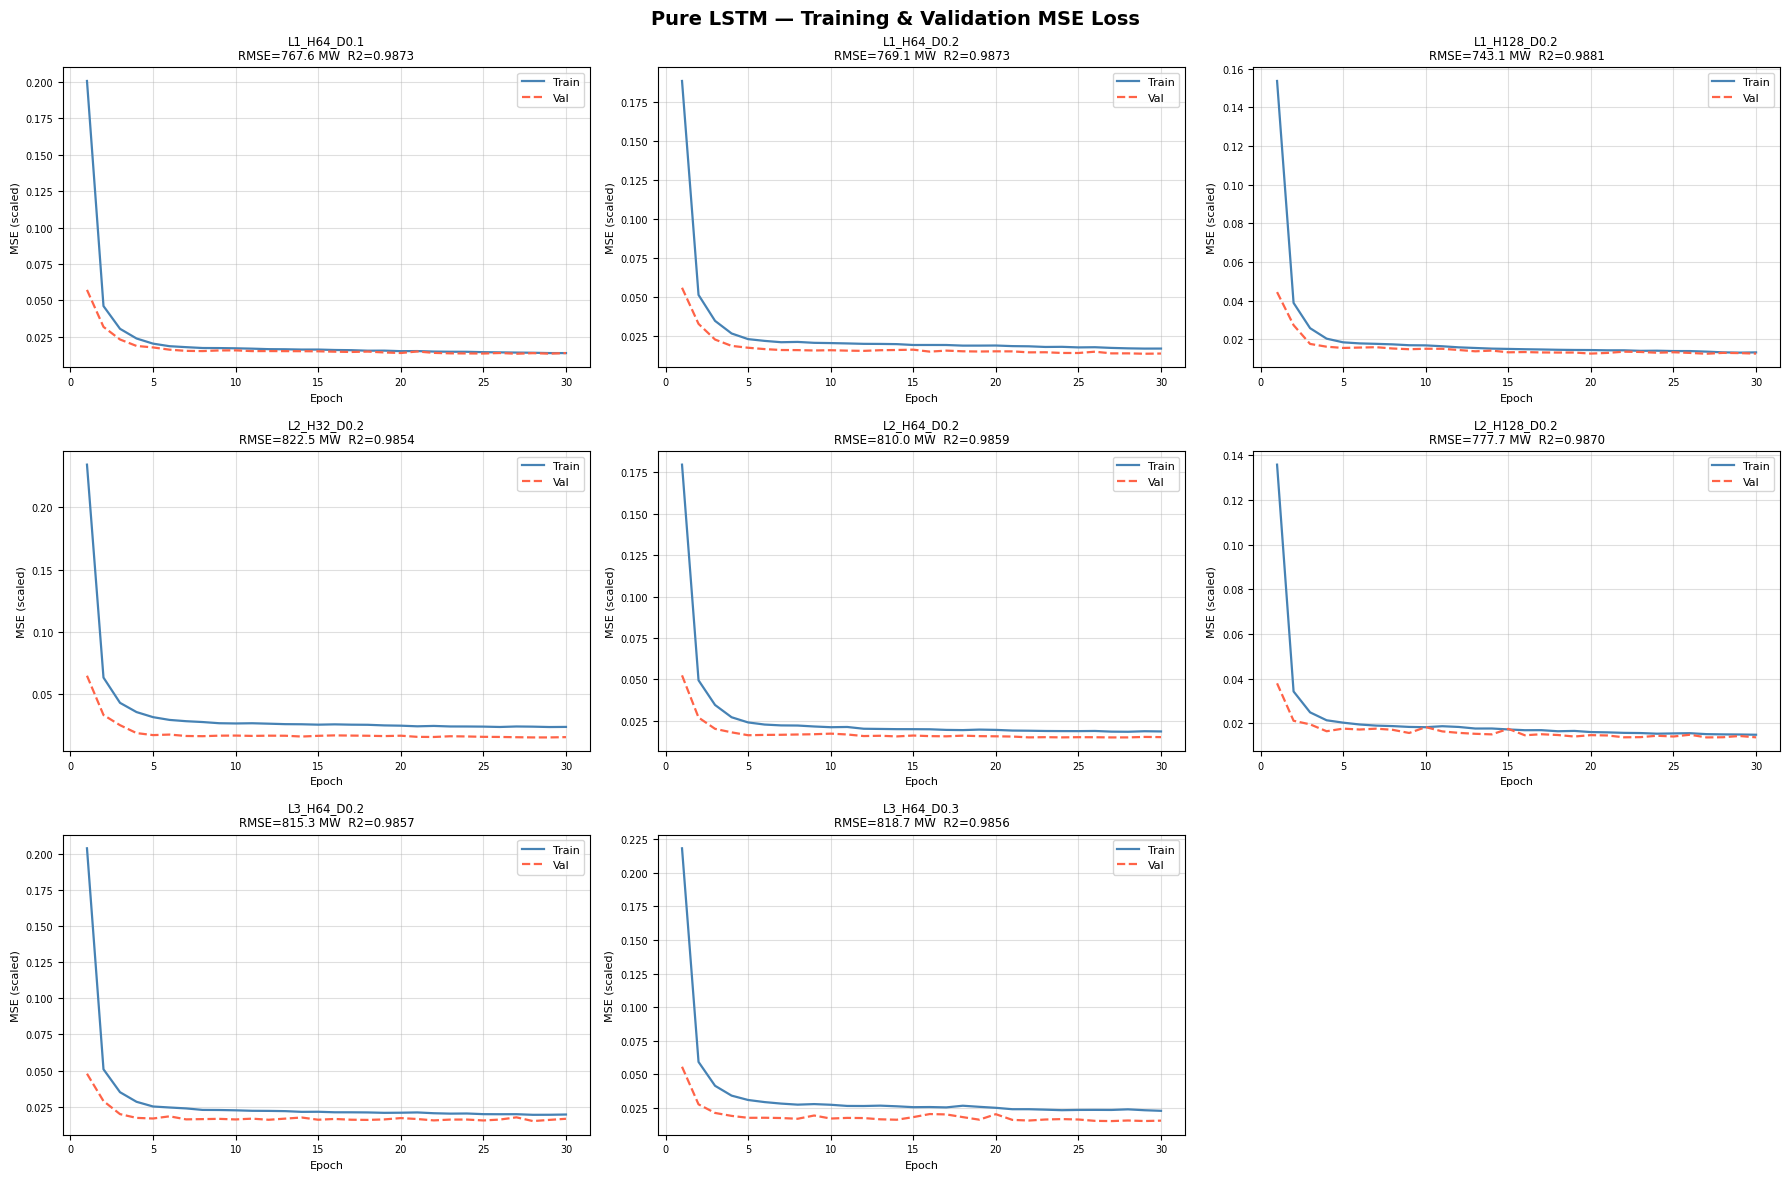

In [ ]:
# ============================================================
# STEP 11.1 — TRAINING & VALIDATION LOSS CURVES
# ============================================================

n = len(histories)
n_cols = 3
n_rows = (n + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()
fig.suptitle(
    'Pure LSTM — Training & Validation MSE Loss',
    fontsize=14, fontweight='bold'
)

for ax, (exp_name, (t_hist, v_hist)) in zip(axes, histories.items()):
    ep = range(1, len(t_hist) + 1)
    ax.plot(ep, t_hist, label='Train', linewidth=1.6, color='steelblue')
    ax.plot(ep, v_hist, label='Val',   linewidth=1.6,
            linestyle='--', color='tomato')
    m = results[exp_name]
    ax.set_title(
        f"{exp_name}\nRMSE={m['RMSE']:.1f} MW  R2={m['R2']:.4f}",
        fontsize=8.5
    )
    ax.set_xlabel('Epoch', fontsize=8)
    ax.set_ylabel('MSE (scaled)', fontsize=8)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.4)
    ax.tick_params(labelsize=7)

for ax in axes[n:]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, '01_loss_curves.png'),
    dpi=150, bbox_inches='tight',
)
plt.show()


### 11.2 — Full Year: Actual vs Predicted (All Configs)

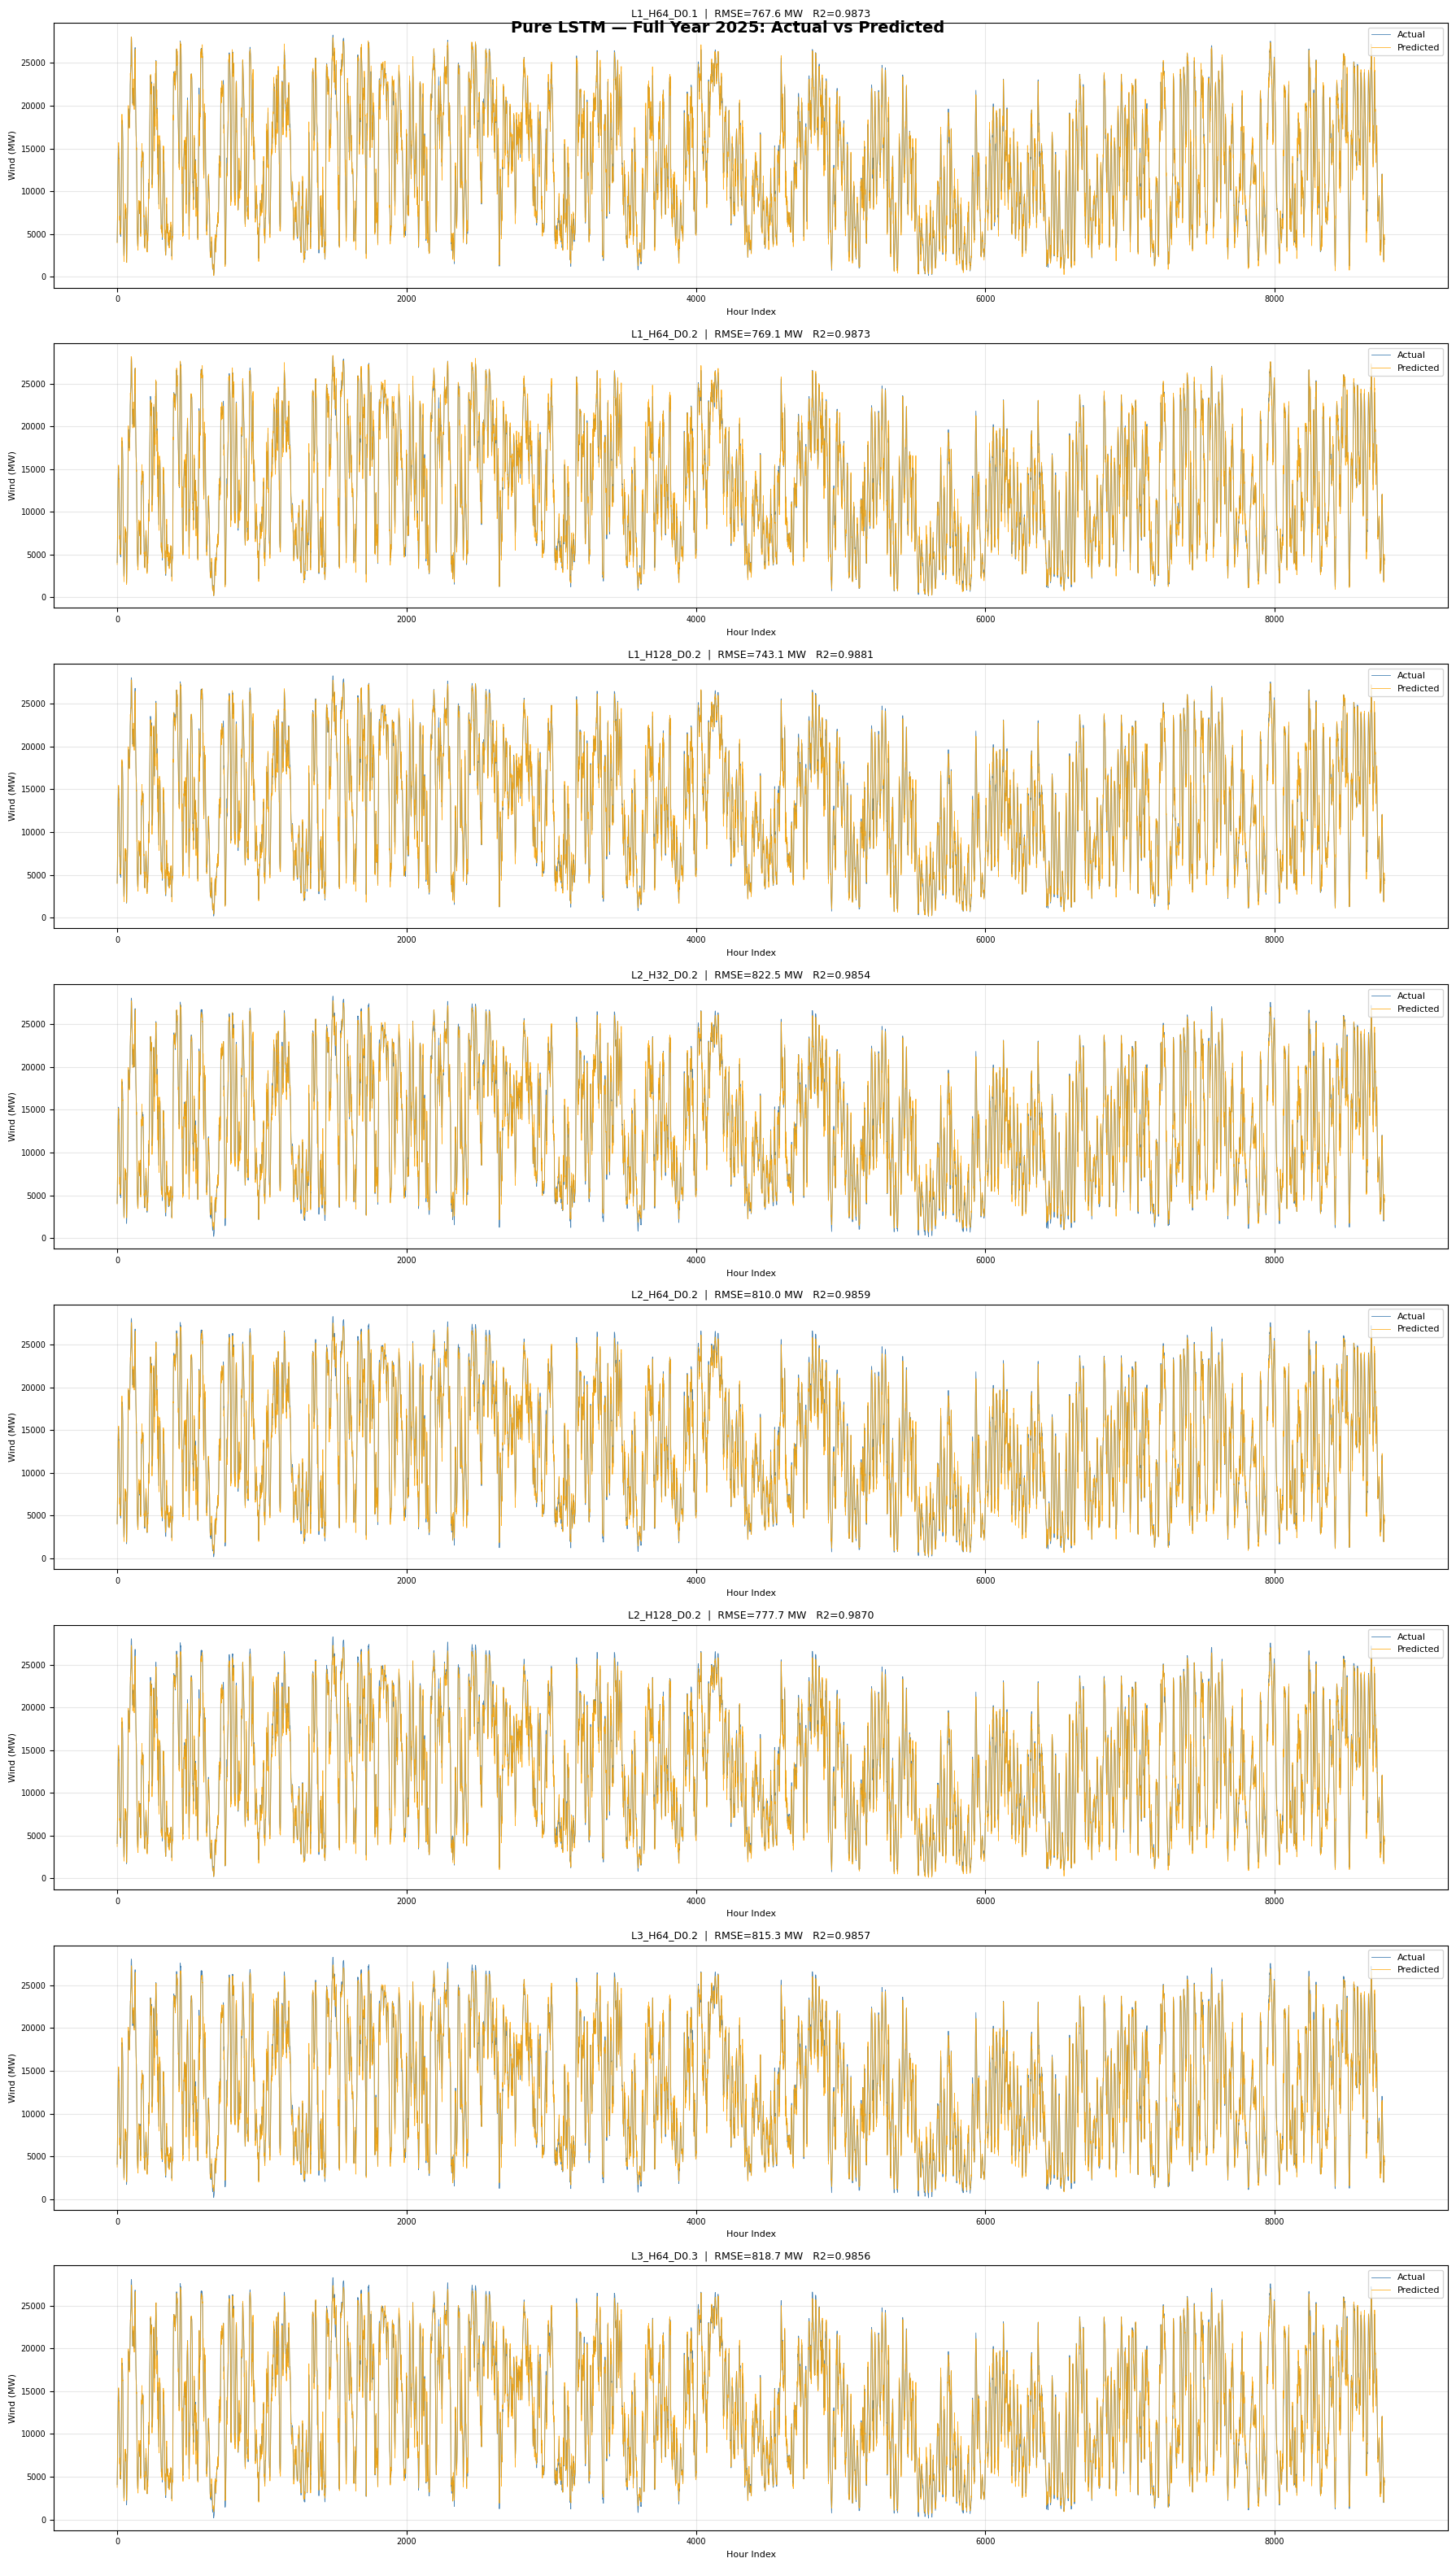

In [ ]:
# ============================================================
# STEP 11.2 — FULL YEAR: ACTUAL VS PREDICTED (ALL CONFIGS)
# ============================================================

n = len(results)
fig, axes = plt.subplots(n, 1, figsize=(18, 4 * n), sharey=False)
fig.suptitle(
    'Pure LSTM — Full Year 2025: Actual vs Predicted',
    fontsize=14, fontweight='bold'
)

for ax, (exp_name, m) in zip(axes, results.items()):
    ax.plot(m['actuals'], label='Actual',
            linewidth=0.6, color='steelblue')
    ax.plot(m['preds'],   label='Predicted',
            linewidth=0.6, color='orange', alpha=0.85)
    ax.set_title(
        f"{exp_name}  |  RMSE={m['RMSE']:.1f} MW   R2={m['R2']:.4f}",
        fontsize=9,
    )
    ax.set_xlabel('Hour Index', fontsize=8)
    ax.set_ylabel('Wind (MW)', fontsize=8)
    ax.legend(loc='upper right', fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.tick_params(labelsize=7)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, '02_full_year_all.png'),
    dpi=110, bbox_inches='tight',
)
plt.show()


### 11.3 — Best Model: Full Year / 7 Days / 2 Days

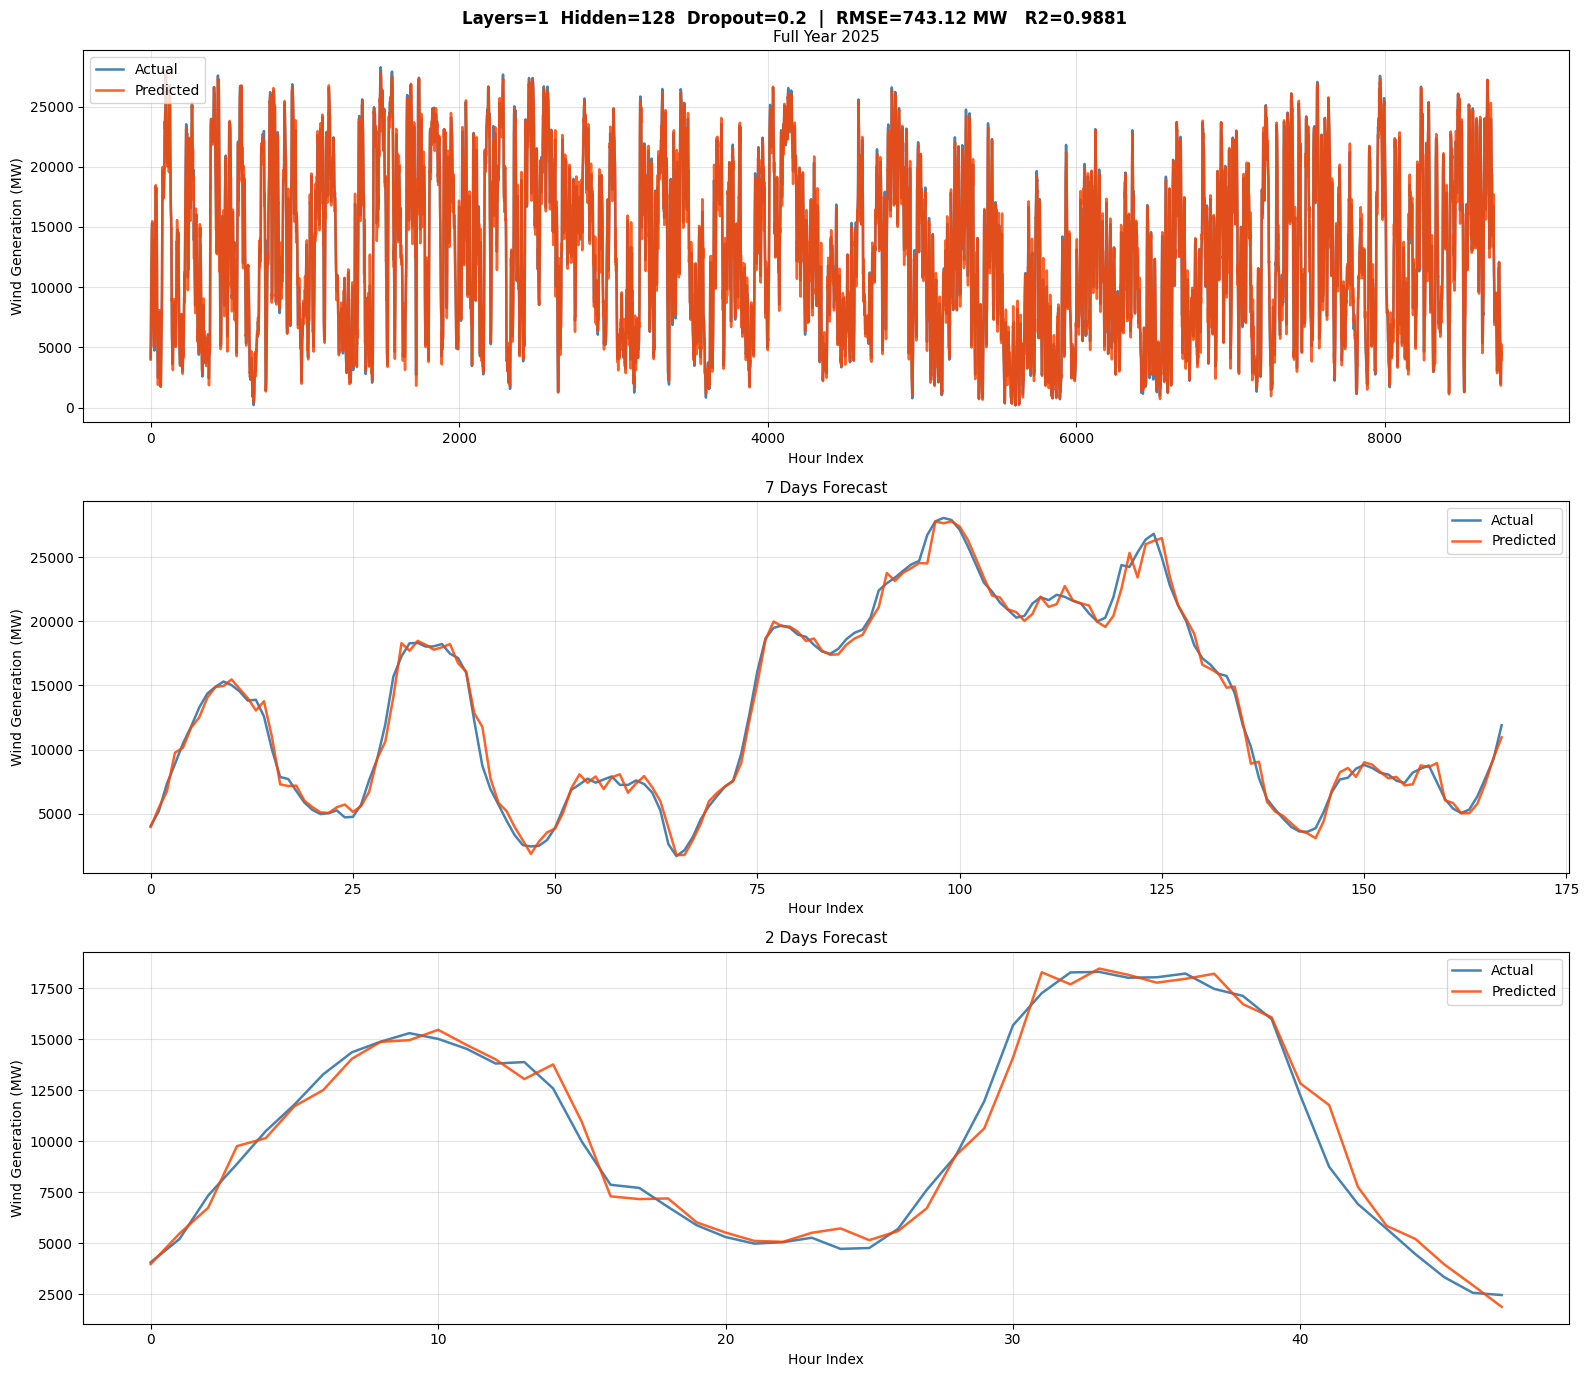

In [ ]:
# ============================================================
# STEP 11.3 — BEST MODEL CLOSE-UP
# ============================================================

HOURS_7D = 24 * 7
HOURS_2D = 24 * 2

best        = results[best_name]
actual_best = best['actuals']
pred_best   = best['preds']

fig, axes = plt.subplots(3, 1, figsize=(16, 14))
fig.suptitle(
    f'Layers={best["layers"]}  Hidden={best["hidden"]}  '
    f'Dropout={best["dropout"]}  |  '
    f'RMSE={best["RMSE"]:.2f} MW   R2={best["R2"]:.4f}',
    fontsize=12, fontweight='bold',
)

slices = [
    (slice(None),        'Full Year 2025'),
    (slice(0, HOURS_7D), '7 Days Forecast'),
    (slice(0, HOURS_2D), '2 Days Forecast'),
]
for ax, (slc, title) in zip(axes, slices):
    ax.plot(actual_best[slc], label='Actual',
            linewidth=1.8, color='steelblue')
    ax.plot(pred_best[slc],   label='Predicted',
            linewidth=1.8, color='orangered', alpha=0.85)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Hour Index')
    ax.set_ylabel('Wind Generation (MW)')
    ax.legend()
    ax.grid(True, alpha=0.35)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, '03_best_model_panels.png'),
    dpi=150, bbox_inches='tight',
)
plt.show()


### 11.4 — Scatter Plots: Actual vs Predicted

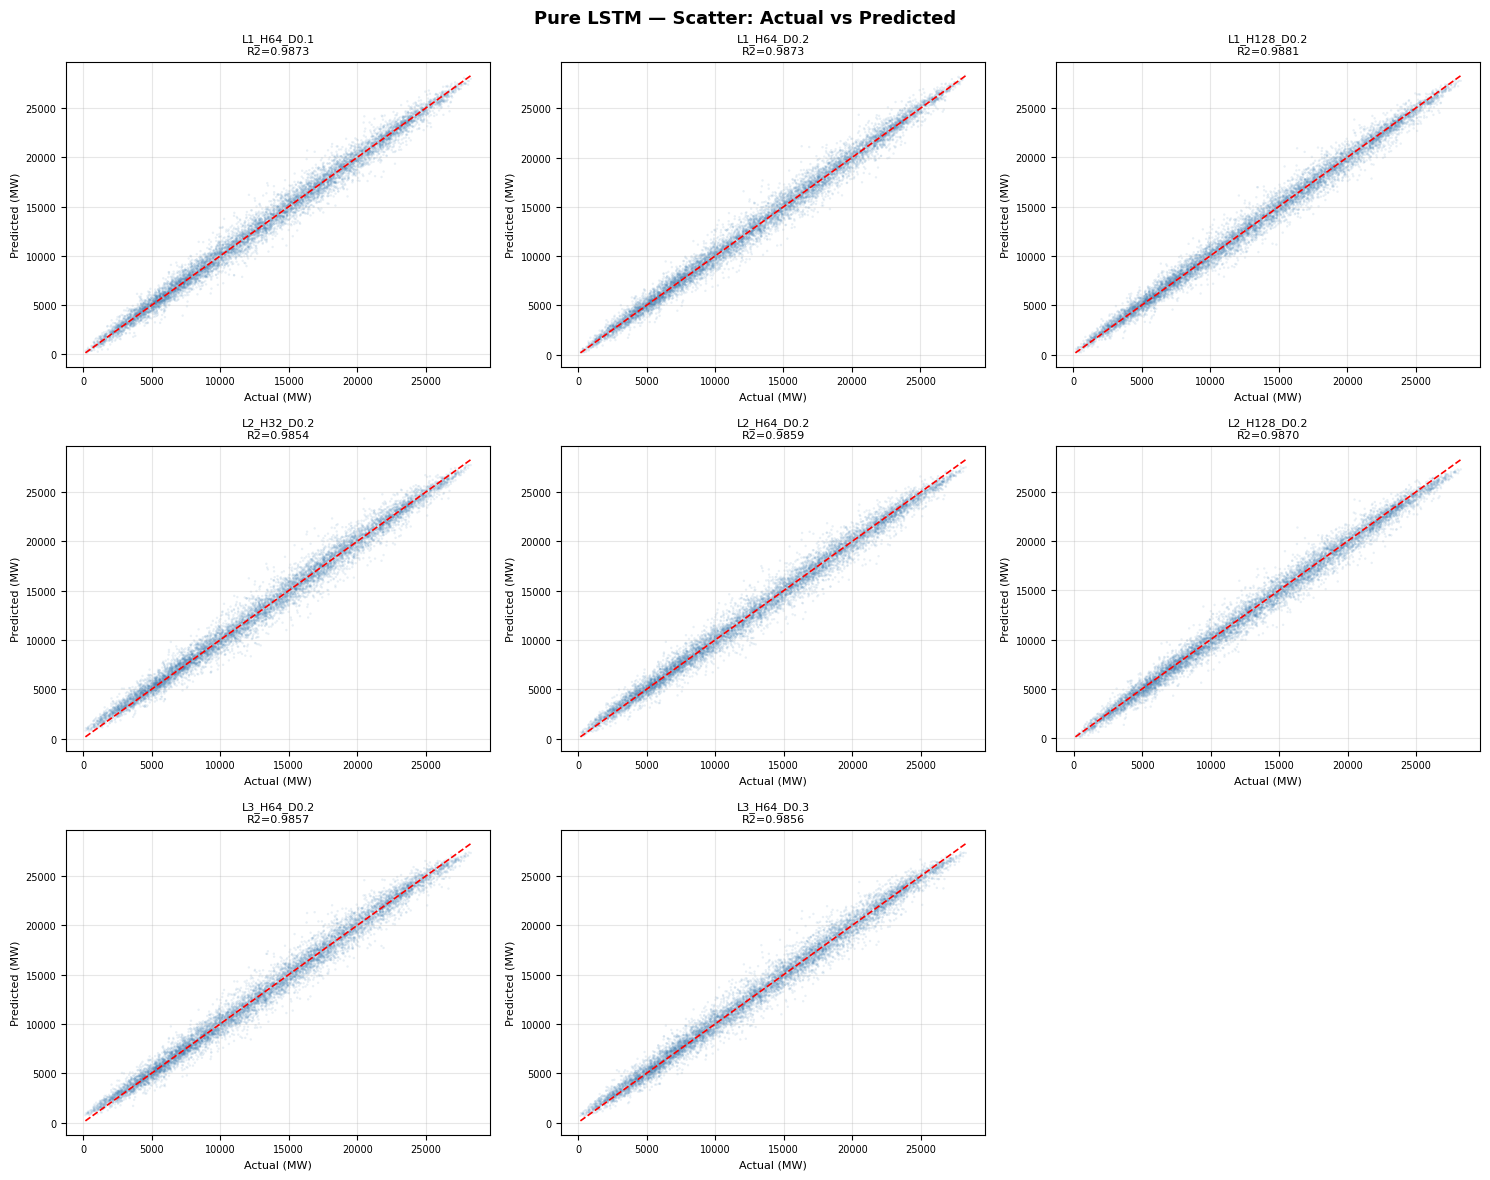

In [ ]:
# ============================================================
# STEP 11.4 — SCATTER PLOTS
# ============================================================

n_cols = 3
n_rows = (len(results) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols,
                         figsize=(5 * n_cols, 4 * n_rows))
axes = axes.flatten()
fig.suptitle('Pure LSTM — Scatter: Actual vs Predicted',
             fontsize=13, fontweight='bold')

for ax, (exp_name, m) in zip(axes, results.items()):
    ax.scatter(
        m['actuals'], m['preds'],
        alpha=0.12, s=3, color='steelblue', edgecolors='none',
    )
    lo = min(m['actuals'].min(), m['preds'].min())
    hi = max(m['actuals'].max(), m['preds'].max())
    ax.plot([lo, hi], [lo, hi], 'r--', linewidth=1.2)
    ax.set_title(f"{exp_name}\nR2={m['R2']:.4f}", fontsize=8)
    ax.set_xlabel('Actual (MW)', fontsize=8)
    ax.set_ylabel('Predicted (MW)', fontsize=8)
    ax.tick_params(labelsize=7)
    ax.grid(True, alpha=0.3)

for ax in axes[len(results):]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, '04_scatter_plots.png'),
    dpi=150, bbox_inches='tight',
)
plt.show()


### 11.5 — Heatmap: RMSE & R² by Layers × Dropout

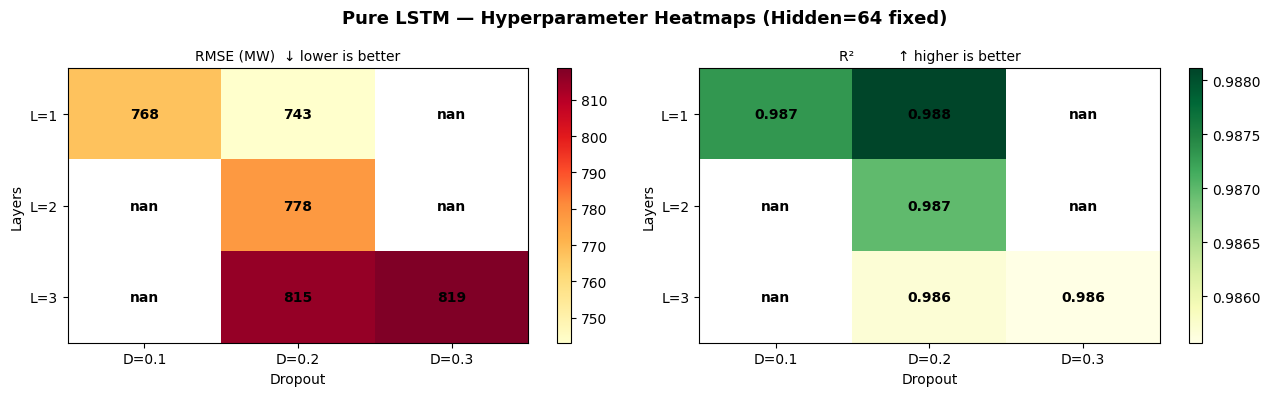

In [ ]:
# ============================================================
# STEP 11.5 — HEATMAP: RMSE & R2 by Layers x Dropout
# (Hidden size is fixed at 64 for every experiment, so the second
#  axis here is Dropout instead of Hidden Units.)
# ============================================================

import itertools

layer_vals   = sorted(set(m['layers']  for m in results.values()))
dropout_vals = sorted(set(m['dropout'] for m in results.values()))

rmse_grid = np.full((len(layer_vals), len(dropout_vals)), np.nan)
r2_grid   = np.full((len(layer_vals), len(dropout_vals)), np.nan)

for exp_name, m in results.items():
    ri = layer_vals.index(m['layers'])
    ci = dropout_vals.index(m['dropout'])
    rmse_grid[ri, ci] = m['RMSE']
    r2_grid[ri, ci]   = m['R2']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('Pure LSTM — Hyperparameter Heatmaps (Hidden=64 fixed)',
             fontsize=13, fontweight='bold')

for ax, grid, title, cmap, fmt in [
    (ax1, rmse_grid, 'RMSE (MW)  ↓ lower is better',  'YlOrRd',  '{:.0f}'),
    (ax2, r2_grid,   'R²          ↑ higher is better', 'YlGn',    '{:.3f}'),
]:
    im = ax.imshow(grid, cmap=cmap, aspect='auto')
    ax.set_xticks(range(len(dropout_vals)))
    ax.set_xticklabels([f'D={d}' for d in dropout_vals])
    ax.set_yticks(range(len(layer_vals)))
    ax.set_yticklabels([f'L={l}' for l in layer_vals])
    ax.set_xlabel('Dropout')
    ax.set_ylabel('Layers')
    ax.set_title(title, fontsize=10)
    plt.colorbar(im, ax=ax)
    for i, j in itertools.product(range(len(layer_vals)), range(len(dropout_vals))):
        ax.text(j, i, fmt.format(grid[i, j]),
                ha='center', va='center', fontsize=10, fontweight='bold',
                color='black')

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, '05_heatmap_layers_dropout.png'),
    dpi=150, bbox_inches='tight',
)
plt.show()


### 11.6 — Bar Charts: MAE / RMSE / R² / MAPE

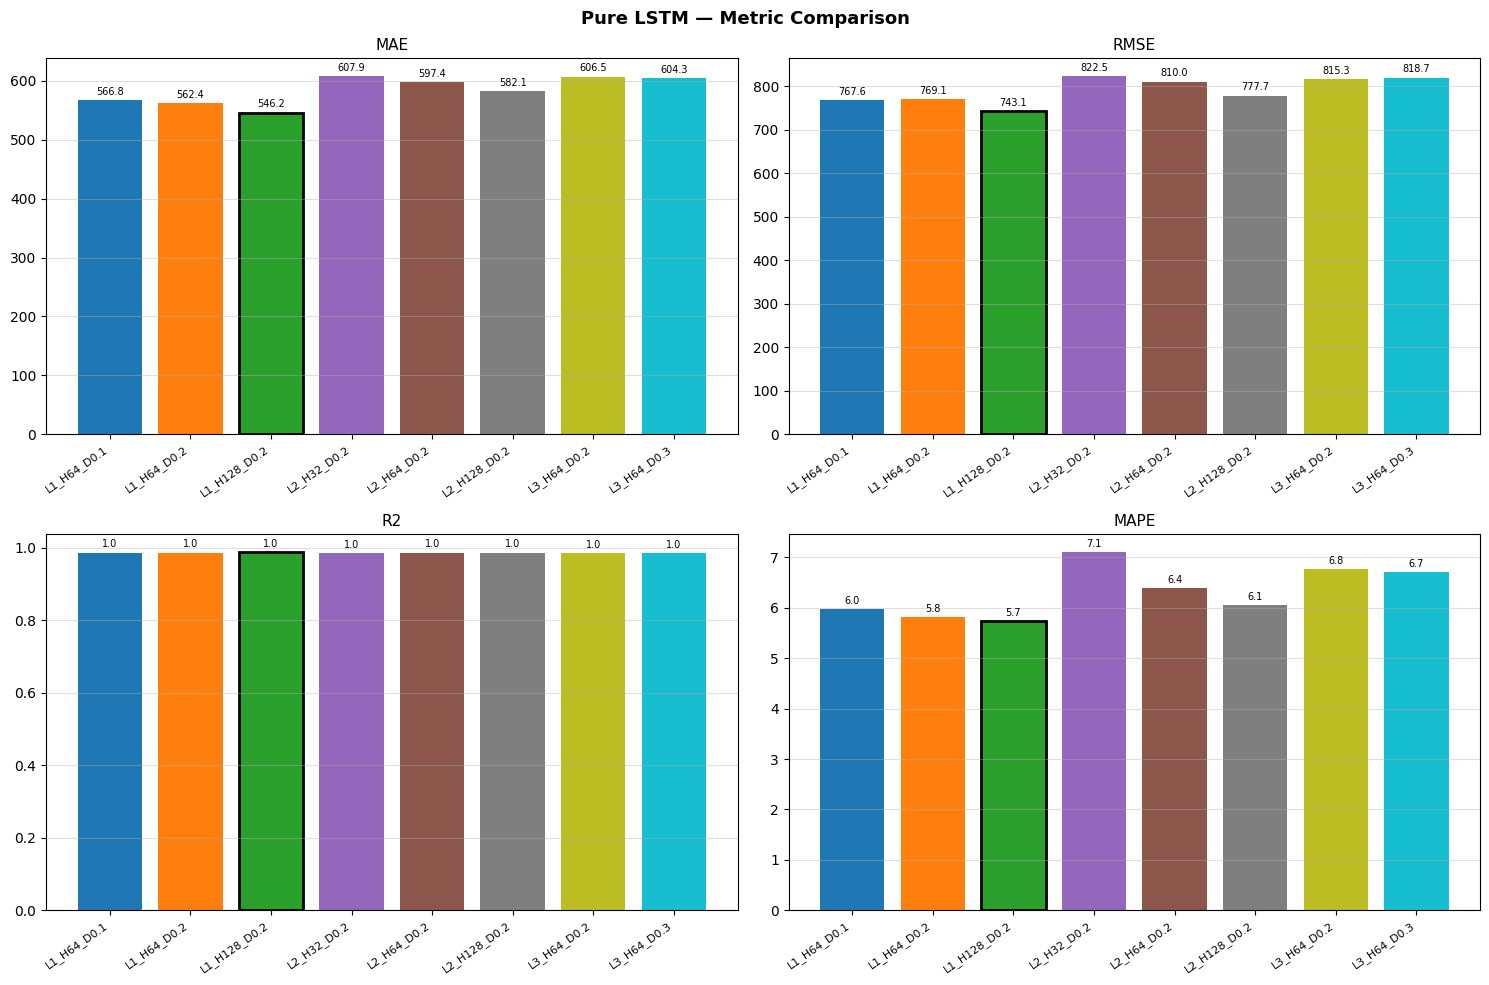

In [ ]:
# ============================================================
# STEP 11.6 — BAR CHART COMPARISON
# ============================================================

metric_names = ['MAE', 'RMSE', 'R2', 'MAPE']
exp_labels   = list(results.keys())
colors = plt.cm.tab10(np.linspace(0, 1, len(exp_labels)))

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Pure LSTM — Metric Comparison',
             fontsize=13, fontweight='bold')

for ax, metric in zip(axes.flatten(), metric_names):
    values = [results[k][metric] for k in exp_labels]
    bars   = ax.bar(range(len(exp_labels)), values, color=colors)

    # highlight the best bar
    best_idx = (
        int(np.argmin(values)) if metric != 'R2'
        else int(np.argmax(values))
    )
    bars[best_idx].set_edgecolor('black')
    bars[best_idx].set_linewidth(2)

    ax.set_xticks(range(len(exp_labels)))
    ax.set_xticklabels(exp_labels, rotation=35, ha='right', fontsize=8)
    ax.set_title(metric, fontsize=11)
    ax.grid(True, axis='y', alpha=0.4)
    for bar, val in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() * 1.01,
            f'{val:.1f}', ha='center', va='bottom', fontsize=7,
        )

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, '06_metric_barcharts.png'),
    dpi=150, bbox_inches='tight',
)
plt.show()


## Step 12 — Final Summary

In [ ]:
# ============================================================
# STEP 12 — FINAL SUMMARY
# ============================================================

best = results[best_name]

print('=' * 70)
print('  WIND LSTM EXPERIMENTS — FINAL SUMMARY')
print('=' * 70)
display(summary_df)

print(f'\n  Best config  : {best_name}')
print(f'  Layers       : {best["layers"]}')
print(f'  Hidden units : {best["hidden"]}')
print(f'  Dropout      : {best["dropout"]}')
print(f'  MAE          : {best["MAE"]:.4f} MW')
print(f'  RMSE         : {best["RMSE"]:.4f} MW')
print(f'  R2           : {best["R2"]:.4f}')
print(f'  MAPE         : {best["MAPE"]:.2f} %')
print(f'\n  Weights & plots saved to: ./{OUTPUT_DIR}/')
print('=' * 70)


  WIND LSTM EXPERIMENTS — FINAL SUMMARY


,Experiment,Layers,Hidden,Dropout,MAE_MW,RMSE_MW,R2,MAPE_pct
0,L1_H128_D0.2,1,128,0.2,546.16,743.12,0.98811,5.75
1,L1_H64_D0.1,1,64,0.1,566.77,767.57,0.98732,5.97
2,L1_H64_D0.2,1,64,0.2,562.43,769.06,0.98727,5.81
3,L2_H128_D0.2,2,128,0.2,582.11,777.75,0.98698,6.06
4,L2_H64_D0.2,2,64,0.2,597.40,809.97,0.98588,6.39
5,L3_H64_D0.2,3,64,0.2,606.53,815.33,0.98569,6.77
6,L3_H64_D0.3,3,64,0.3,604.31,818.68,0.98557,6.71
7,L2_H32_D0.2,2,32,0.2,607.86,822.51,0.98543,7.10



  Best config  : L1_H128_D0.2
  Layers       : 1
  Hidden units : 128
  Dropout      : 0.2
  MAE          : 546.1626 MW
  RMSE         : 743.1202 MW
  R2           : 0.9881
  MAPE         : 5.75 %

  Weights & plots saved to: ./wind_results/
